In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, fixed
from pathlib import Path
from galaxy_sidm.io import load_config
from galaxy_sidm.mock.tables import assemble, CONFIG, sparc_rings, vcirc_at, vcirc_curves, gas_disc_sample, sparc_mod_vflat
from galaxy_sidm.mock.barolo import rings_file
from galaxy_sidm.mock import CubeParams

cfg = load_config(None)
MARTINI = Path(cfg["paths"]["scratch_processed"]).parent / "martini"
TOL = 0.05 # same speed: fastest <= 1.05 x slowest
MIN_RINGS = 3 # fewest rings for a v_flat
TOL_RETRY = 0.10 # second try for galaxies with no v_flat at TOL

discs = pd.DataFrame(assemble(cfg, exclude_yaml=CONFIG / "problematic_discs.yaml", flat_tol=TOL))
discs

,model,snap,z,sub_id,Mstar,M200c,M_neutral,v_flat,IsDisc,bbarolo_rc
0,CDM,17,5.0,1202,1.877190e+10,8.049343e+11,3.028941e+10,NaN,1,0
1,CDM,21,4.0,668,7.342890e+10,2.883971e+12,6.222788e+10,NaN,1,0
2,CDM,21,4.0,1056,8.674810e+10,1.497082e+12,2.676411e+10,NaN,1,0
3,CDM,21,4.0,2028,4.158000e+10,1.440978e+12,2.691134e+10,337.967250,1,0
4,CDM,21,4.0,1724,3.781570e+10,1.269413e+12,2.563276e+10,NaN,1,0
...,...,...,...,...,...,...,...,...,...,...
3885,vSIDM,67,0.5,75970,1.416590e+10,6.718645e+11,1.277089e+10,NaN,1,0
3886,vSIDM,67,0.5,77196,1.959850e+10,5.471949e+11,3.734745e+09,NaN,1,0
3887,vSIDM,67,0.5,71107,6.412350e+09,4.570422e+11,1.148868e+10,139.673333,1,0
3888,vSIDM,67,0.5,82374,1.358250e+10,4.709615e+11,5.004369e+09,155.358000,1,0


In [2]:
def curve(model, z, sub):
    """Radius (kpc) and VROT (km/s) of the final fit's rings."""
    lines = rings_file(MARTINI / f"z{z:g}" / model / f"gal_{sub:06d}" / "bbarolo").read_text().splitlines()
    rows = [l.split() for l in lines if l.strip() and not l.startswith("#")]
    return np.array([float(r[0]) for r in rows]), np.array([float(r[2]) for r in rows])


def short_side(model, z, sub):
    """Radius (kpc) where the emission ends on the shorter side of the major axis; nan if one side has none."""
    info = json.loads((MARTINI / f"z{z:g}" / model / f"gal_{sub:06d}" / "info.json").read_text())
    ends = info["pv_emission_end_arcsec"]
    if None in ends:
        return np.nan
    return np.radians(min(ends) / 3600) * CubeParams().distance.to_value("kpc")


def plot_page(sel, page):
    """Rotation curves of rows 24 * page to 24 * page + 23 of sel (orange: the rings of the SPARC_mod v_flat)."""
    part = sel.iloc[24 * page: 24 * (page + 1)]
    print(f"showing {24 * page} to {24 * page + len(part)}")
    fig, axes = plt.subplots(4, 6, figsize=(18, 11), constrained_layout=True)
    for ax, (_, g) in zip(axes.flat, part.iterrows()):
        R, v = curve(g["model"], g["z"], g["subID"])
        _, used = sparc_mod_vflat(v, TOL, MIN_RINGS)
        ax.plot(R, v, "o-", ms=3, color="C0")
        ax.plot(R[used], v[used], "o", ms=5, color="C1")
        if np.isfinite(g["vflat_SPARC"]):
            ax.axhline(g["vflat_SPARC"], color="k", ls="--", lw=1)
        if np.isfinite(g["vflat_SPARC_mod"]):
            ax.axhline(g["vflat_SPARC_mod"], color="k", lw=1)
        ax.set_title(f"{g['model']} z = {g['z']:g} {g['subID']}", fontsize=12)
        ax.set_ylim(0)
    for ax in axes.flat[len(part):]:
        ax.set_visible(False)
    plt.show()

In [3]:
rows, one_sided = [], []
for g in discs.itertuples():
    r_short = short_side(g.model, g.z, g.sub_id)
    if np.isnan(r_short):
        one_sided.append(f"{g.model} z{g.z:g} {g.sub_id}")
        continue
    R, v = curve(g.model, g.z, g.sub_id)
    vf, used = sparc_mod_vflat(v, TOL, MIN_RINGS)
    vf_retry = np.nan
    if np.isnan(vf):# and np.isnan(g.v_flat): #comment out if you retry for just 'neiter'
        vf_retry, _ = sparc_mod_vflat(v, TOL_RETRY, MIN_RINGS)
    rows.append(dict(model=g.model, snap=g.snap, z=g.z, subID=g.sub_id, rings=len(v), R_short=r_short,
                     vflat_SPARC=g.v_flat, vflat_SPARC_mod=vf, vflat_SPARC_mod_retry=vf_retry, rings_used=len(used)))
tab = pd.DataFrame(rows)
print(f"{len(one_sided)} galaxies with emission on one side only, left out: {one_sided}")
tab

0 galaxies with emission on one side only, left out: []


,model,snap,z,subID,rings,R_short,vflat_SPARC,vflat_SPARC_mod,vflat_SPARC_mod_retry,rings_used
0,CDM,17,5.0,1202,6,3.878509,NaN,NaN,NaN,0
1,CDM,21,4.0,668,13,3.151289,NaN,299.344000,NaN,5
2,CDM,21,4.0,1056,5,2.787679,NaN,NaN,NaN,0
3,CDM,21,4.0,2028,5,3.514899,337.967250,337.967250,NaN,4
4,CDM,21,4.0,1724,9,2.666475,NaN,291.305333,NaN,3
...,...,...,...,...,...,...,...,...,...,...
3885,vSIDM,67,0.5,75970,24,14.180800,NaN,164.236000,NaN,6
3886,vSIDM,67,0.5,77196,14,8.969053,NaN,179.750500,NaN,4
3887,vSIDM,67,0.5,71107,15,8.726646,139.673333,139.673333,NaN,3
3888,vSIDM,67,0.5,82374,13,6.060171,155.358000,154.972250,NaN,4


In [4]:
# agreement between the rules (same = within 1%)
sparc, mod, retry = tab["vflat_SPARC"], tab["vflat_SPARC_mod"], tab["vflat_SPARC_mod_retry"]
both = sparc.notna() & mod.notna()
same = both & (abs(mod / sparc - 1) <= 0.01)
tab["case"] = np.select([same, both, mod.notna(), retry.notna(), sparc.notna()],
                        ["same", "different", "only SPARC_mod", f"SPARC_mod {TOL_RETRY:.0%}", "only SPARC"], "neither")
cases = pd.crosstab([tab["model"], tab["z"]], tab["case"], margins=True)
cases

case       SPARC_mod 10%  different  neither  only SPARC  only SPARC_mod  \
model z                                                                    
CDM   0.5             23        125       28           2             179   
      1.0             39         92       41           5             155   
      2.0             55         37       46           5              69   
      3.0             29          8       34           3              23   
      4.0              2          1       12           0               5   
      5.0              0          0        1           0               0   
SIDM1 0.5             34        135       34           3             175   
      1.0             47        100       56           6             166   
      2.0             58         43       65           2              84   
      3.0             29          9       53           5              19   
      4.0              4          2       13           0               8   
      5.0              1          1        2           0               0   
vSIDM 0.5             35        109       29           1             177   
      1.0             45         78       48           4             168   
      2.0             55         38       59           6              72   
      3.0             27          7       40           5              17   
      4.0              7          1        8           2               1   
      5.0              1          0        1           0               0   
All                  491        786      570          49            1318   

case       same   All  
model z                
CDM   0.5    82   439  
      1.0    70   402  
      2.0    30   242  
      3.0    17   114  
      4.0     2    22  
      5.0     0     1  
SIDM1 0.5   103   484  
      1.0    86   461  
      2.0    41   293  
      3.0    13   128  
      4.0     6    33  
      5.0     0     4  
vSIDM 0.5    89   440  
      1.0    82   425  
      2.0    33   263  
      3.0    16   112  
      4.0     5    24  
      5.0     1     3  
All         676  3890

In [17]:
case = "only SPARC_mod"
show = tab[tab["case"] == case]
print(f"{len(show)} galaxies in '{case}'")
interact(plot_page, sel=fixed(show), page=IntSlider(min=0, max=max((len(show) - 1) // 24, 0), continuous_update=False));

1318 galaxies in 'only SPARC_mod'


interactive(children=(IntSlider(value=0, continuous_update=False, description='page', max=54), Output()), _dom…

In [6]:
# tab.loc[tab["case"] == "neither", ["model", "z", "subID"]].to_csv(Path.home() / "tmp" / "pv_neither.txt", sep=" ", header=False, index=False)

In [7]:
# does galaxy 87165 (CDM z0.5) have a calculable vflat?
print(tab[(tab["model"] == "CDM") & (tab["z"] == 0.5) & (tab["subID"] == 87165)])

     model  snap    z  subID  rings   R_short  vflat_SPARC  vflat_SPARC_mod  \
1014   CDM    67  0.5  87165      3  1.333238          NaN              NaN   

      vflat_SPARC_mod_retry  rings_used     case  
1014                    NaN           0  neither  


      model    z  subID  vflat_SPARC  vflat_SPARC_mod
747     CDM  1.0  45199   107.617000       325.349250
2935  vSIDM  2.0  16266   116.500750       259.386667
1961  SIDM1  1.0  49823   108.530333       235.415333
590     CDM  1.0  44071   143.562000       287.644500
1293  SIDM1  3.0   6656    88.944333       178.003333
1770  SIDM1  1.0  77809    69.945750       137.627000
2135  SIDM1  1.0  79354    62.623667       122.990750
1787  SIDM1  1.0  25893   211.772000       383.947333
1469  SIDM1  2.0  35619   285.732667       158.184250
3256  vSIDM  1.0  50316   128.378333       228.997750


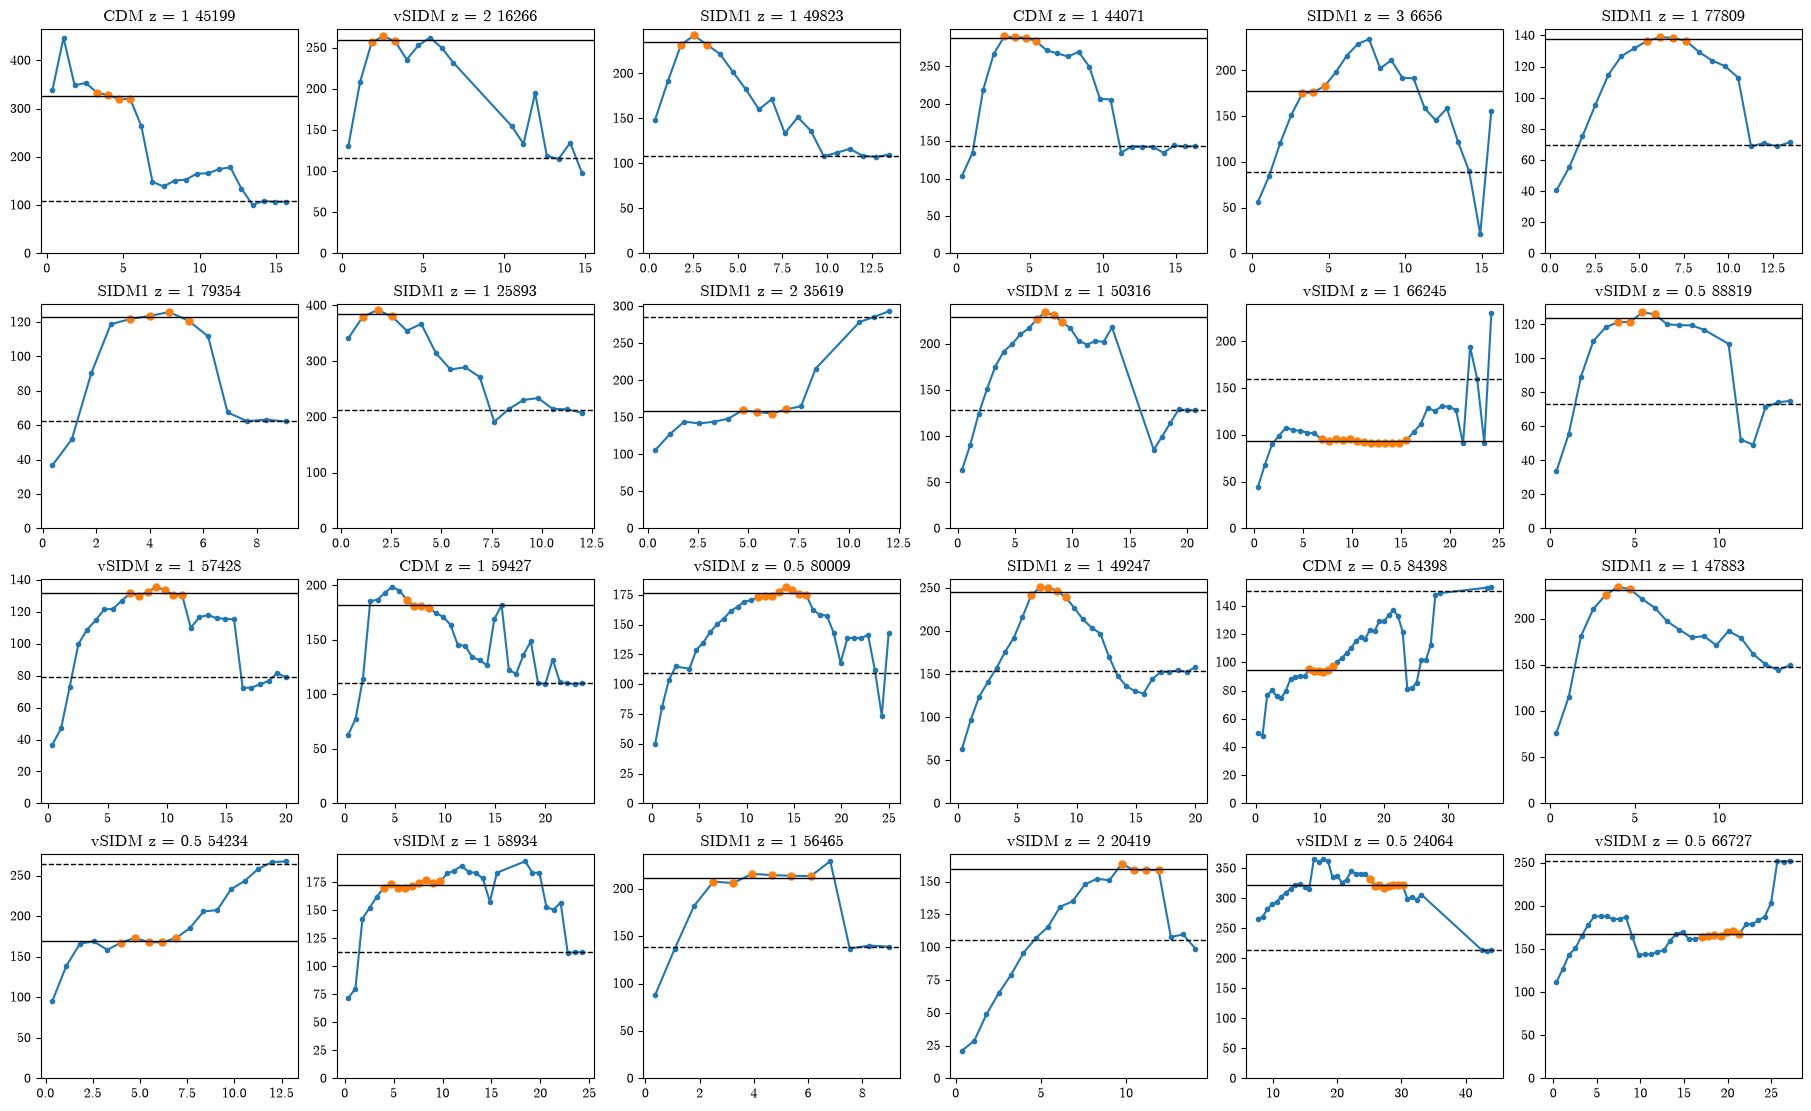

In [8]:
#print biggest difference between vflat_SPARC and vflat_SPARC_mod
diff = tab["vflat_SPARC_mod"] - tab["vflat_SPARC"]
diff_frac = diff / tab[["vflat_SPARC", "vflat_SPARC_mod"]].max(axis=1)
biggest_diff = np.sort(diff[tab["case"] == "different"])[-10:][::-1]

#print the names of the galaxies with the biggest differences
print(tab.loc[diff_frac.abs().nlargest(10).index, ["model", "z", "subID", "vflat_SPARC", "vflat_SPARC_mod"]])

#show the rotation curves of the galaxies with the biggest differences
fig, axes = plt.subplots(4, 6, figsize=(18, 11), constrained_layout=True)
for ax, (_, g) in zip(axes.flat, tab.loc[diff_frac.abs().nlargest(24).index].iterrows()):
    R, v = curve(g["model"], g["z"], g["subID"])
    _, used = sparc_mod_vflat(v, TOL, MIN_RINGS)
    ax.plot(R, v, "o-", ms=3, color="C0")
    ax.plot(R[used], v[used], "o", ms=5, color="C1")
    if np.isfinite(g["vflat_SPARC"]):
        ax.axhline(g["vflat_SPARC"], color="k", ls="--", lw=1)
    if np.isfinite(g["vflat_SPARC_mod"]):
        ax.axhline(g["vflat_SPARC_mod"], color="k", lw=1)
    ax.set_title(f"{g['model']} z = {g['z']:g} {g['subID']}", fontsize=12)
    ax.set_ylim(0)
for ax in axes.flat[len(show):]:
    ax.set_visible(False)
plt.show()

In [9]:
tab.loc[diff_frac.abs().nlargest(100).index, ["model", "z", "subID", "vflat_SPARC", "vflat_SPARC_mod"]]

,model,z,subID,vflat_SPARC,vflat_SPARC_mod
747,CDM,1.0,45199,107.617000,325.349250
2935,vSIDM,2.0,16266,116.500750,259.386667
1961,SIDM1,1.0,49823,108.530333,235.415333
590,CDM,1.0,44071,143.562000,287.644500
1293,SIDM1,3.0,6656,88.944333,178.003333
...,...,...,...,...,...
631,CDM,1.0,65122,192.837500,151.072444
760,CDM,1.0,69899,121.582000,155.090250
3534,vSIDM,0.5,37027,259.992333,330.574800
143,CDM,2.0,35306,194.761333,153.291400


In [10]:
vrot_rule = "SPARC_mod"

vcirc = {(m, s): vcirc_curves(cfg, m, s) for m, s in set(zip(tab["model"], tab["snap"]))}
rows, missing = [], []
for g in tab.itertuples():
    if g.subID not in vcirc[(g.model, g.snap)]:
        missing.append(f"{g.model} z{g.z:g} {g.subID}")
        continue
    R, v = curve(g.model, g.z, g.subID)
    if vrot_rule == "SPARC_mod":
        _, used = sparc_mod_vflat(v, TOL, MIN_RINGS)
    elif vrot_rule == "SPARC":
        used = np.arange(len(v) - sparc_rings(v, TOL), len(v))
    else:
        raise ValueError(vrot_rule)
    if len(used) == 0:
        continue
    vc = vcirc_at(R[used], *vcirc[(g.model, g.snap)][g.subID])
    rows.append(dict(model=g.model, z=g.z, subID=g.subID, vflat_rot=v[used].mean(), vflat_circ=vc.mean()))
comp = pd.DataFrame(rows)
comp["ratio"] = comp["vflat_rot"] / comp["vflat_circ"]
print(f"{len(missing)} discs without a v_circ curve: {missing}")
print(f"{comp['ratio'].isna().sum()} discs with flat rings outside the v_circ curve")
comp

0 discs without a v_circ curve: []
3 discs with flat rings outside the v_circ curve


,model,z,subID,vflat_rot,vflat_circ,ratio
0,CDM,4.0,668,299.344000,386.293287,0.774914
1,CDM,4.0,2028,337.967250,347.078925,0.973748
2,CDM,4.0,1724,291.305333,342.903251,0.849526
3,CDM,4.0,2127,260.881333,293.028772,0.890293
4,CDM,4.0,4381,234.227200,252.181283,0.928805
...,...,...,...,...,...,...
2775,vSIDM,0.5,75970,164.236000,172.267922,0.953375
2776,vSIDM,0.5,77196,179.750500,179.492078,1.001440
2777,vSIDM,0.5,71107,139.673333,133.057058,1.049725
2778,vSIDM,0.5,82374,154.972250,168.333843,0.920624


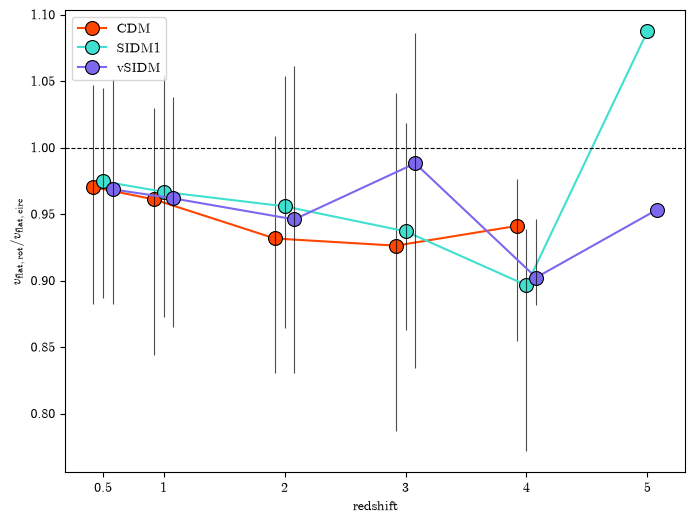

In [11]:
colors = {"CDM": "orangered", "SIDM1": "turquoise", "vSIDM": "mediumslateblue"}
offset = {"CDM": -0.08, "SIDM1": 0.0, "vSIDM": 0.08}
redshifts = sorted(comp["z"].unique())
fig, ax = plt.subplots(figsize=(8, 6))
for model in ["CDM", "SIDM1", "vSIDM"]:
    medians, p16, p84 = [], [], []
    for z in redshifts:
        r = comp.loc[(comp["model"] == model) & (comp["z"] == z), "ratio"].dropna()
        lo, med, hi = np.percentile(r, [16, 50, 84]) if len(r) else (np.nan, np.nan, np.nan)
        medians.append(med)
        p16.append(lo)
        p84.append(hi)
    x = np.array(redshifts) + offset[model]
    medians, p16, p84 = np.array(medians), np.array(p16), np.array(p84)
    ax.plot(x, medians, "o-", markersize=10, label=model, color=colors[model], markeredgecolor="k", markeredgewidth=0.8)
    ax.errorbar(x, medians, yerr=[medians - p16, p84 - medians], fmt="none", ecolor="k", lw=0.8, capsize=0, alpha=0.7)
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xticks(redshifts, [f"{z:g}" for z in redshifts])
ax.set_xlabel("redshift")
ax.set_ylabel(r"$v_{\rm flat,rot} / v_{\rm flat,circ}$")
ax.legend()
plt.show()

In [12]:
channel = CubeParams().channel_width.to_value("km/s")
over, under = f"> {channel:g} km/s", f"<= {channel:g} km/s"
sparc, mod = tab["vflat_SPARC"], tab["vflat_SPARC_mod"]
both = sparc.notna() & mod.notna()
big = both & (abs(mod - sparc) > channel)
tab["difference"] = np.select([big, both, sparc.notna(), mod.notna()], [over, under, "only SPARC", "only SPARC_mod"], "neither")
table = pd.crosstab([tab["model"], tab["z"]], tab["difference"], margins=True)
table[f"fraction {over}"] = table[over] / (table['All'])
table

difference  <= 30 km/s  > 30 km/s  neither  only SPARC  only SPARC_mod   All  \
model z                                                                        
CDM   0.5          188         19       45           8             179   439   
      1.0          142         20       66          19             155   402   
      2.0           55         12       81          25              69   242   
      3.0           24          1       51          15              23   114   
      4.0            3          0       13           1               5    22   
      5.0            0          0        1           0               0     1   
SIDM1 0.5          216         22       60          11             175   484   
      1.0          158         28       80          29             166   461   
      2.0           79          5      111          14              84   293   
      3.0           17          5       76          11              19   128   
      4.0            8          0       17           0               8    33   
      5.0            1          0        3           0               0     4   
vSIDM 0.5          164         34       53          12             177   440   
      1.0          138         22       81          16             168   425   
      2.0           64          7      105          15              72   263   
      3.0           22          1       62          10              17   112   
      4.0            5          1       12           5               1    24   
      5.0            1          0        1           1               0     3   
All               1285        177      918         192            1318  3890   

difference  fraction > 30 km/s  
model z                         
CDM   0.5             0.043280  
      1.0             0.049751  
      2.0             0.049587  
      3.0             0.008772  
      4.0             0.000000  
      5.0             0.000000  
SIDM1 0.5             0.045455  
      1.0             0.060738  
      2.0             0.017065  
      3.0             0.039062  
      4.0             0.000000  
      5.0             0.000000  
vSIDM 0.5             0.077273  
      1.0             0.051765  
      2.0             0.026616  
      3.0             0.008929  
      4.0             0.041667  
      5.0             0.000000  
All                   0.045501

In [13]:
max_asym, max_res = 0.25, 3
gal = gas_disc_sample(cfg)
discdisc = tab.merge(gal[["model", "z", "subID", "A_sq", "mix"]], on=["model", "z", "subID"], how="left")
discdisc = discdisc[(discdisc["A_sq"] < max_asym) & (discdisc["mix"] < max_res)]
discdisc_cases = pd.crosstab([discdisc["model"], discdisc["z"]], discdisc["case"], margins=True)
discdisc_cases

case       SPARC_mod 10%  different  neither  only SPARC  only SPARC_mod  \
model z                                                                    
CDM   0.5             19         39       22           0              60   
      1.0             20         29       32           2              68   
      2.0             33         21       32           4              35   
      3.0             14          6       17           1              12   
      4.0              2          1       10           0               2   
SIDM1 0.5             20         40       24           3              55   
      1.0             31         34       45           6              55   
      2.0             34         19       40           1              37   
      3.0             17          3       43           4              10   
      4.0              2          1        7           0               5   
      5.0              0          0        1           0               0   
vSIDM 0.5             26         29       19           1              67   
      1.0             34         26       29           4              58   
      2.0             32         18       40           1              37   
      3.0             11          3       25           3              10   
      4.0              6          0        4           1               1   
      5.0              1          0        0           0               0   
All                  302        269      390          31             512   

case       same   All  
model z                
CDM   0.5    38   178  
      1.0    23   174  
      2.0    18   143  
      3.0     9    59  
      4.0     2    17  
SIDM1 0.5    42   184  
      1.0    39   210  
      2.0    25   156  
      3.0     8    85  
      4.0     4    19  
      5.0     0     1  
vSIDM 0.5    32   174  
      1.0    40   191  
      2.0    15   143  
      3.0     8    60  
      4.0     3    15  
      5.0     0     1  
All         306  1810

In [14]:
#out of these galaxies, how many have a difference > channel?
discdisc["difference"] = discdisc["difference"].replace({"only SPARC": under, "only SPARC_mod": under, "neither": under})
pd.crosstab([discdisc["model"], discdisc["z"]], discdisc["difference"], margins=True)

difference  <= 30 km/s  > 30 km/s   All
model z                                
CDM   0.5          174          4   178
      1.0          169          5   174
      2.0          138          5   143
      3.0           58          1    59
      4.0           17          0    17
SIDM1 0.5          180          4   184
      1.0          207          3   210
      2.0          155          1   156
      3.0           84          1    85
      4.0           19          0    19
      5.0            1          0     1
vSIDM 0.5          167          7   174
      1.0          183          8   191
      2.0          141          2   143
      3.0           59          1    60
      4.0           15          0    15
      5.0            1          0     1
All               1768         42  1810

In [15]:
#plot the rotation curves of the galaxies with A_sq < max_asym and mix < max_res
case = "neither"
show = discdisc[discdisc["case"] == case]
print(f"{len(show)} galaxies in '{case}'")
interact(plot_page, sel=fixed(show), page=IntSlider(min=0, max=max((len(show) - 1) // 24, 0), continuous_update=False));

390 galaxies in 'neither'


interactive(children=(IntSlider(value=0, continuous_update=False, description='page', max=16), Output()), _dom…

In [16]:
# discdisc.loc[tab["case"] == "neither", ["model", "z", "subID"]].to_csv(Path.home() / "tmp" / "pv_neither_disc.txt", sep=" ", header=False, index=False)